# Hoja de Trabajo 6 – Task 3
**CC2017 – Modelación y Simulación, Sección 10**

- José Gerardo Ruiz García – 23719
- Gerardo André Fernández Cruz – 23763
- Juan Diego Solís Martínez – 23720

Modelo de un lago con reciclaje interno de nutrientes, donde $x(t)$ es la concentración de nutrientes en el agua y $a$ es la carga externa:

$$\dot x = a - b\,x + \frac{x^2}{x^2+1} = f(x;a), \qquad b = 0.52 + 0.03\,((g-1)\bmod 3)$$

con $r=1$, $h=1$ y $p=2$ ya sustituidos. Este Task estudia el punto de no retorno (colapso e histéresis) y las señales de alerta temprana. Los integradores (RK4 y Euler-Maruyama) están programados desde cero y `solve_ivp` no se usa.

## Parámetros del grupo

Se calcula $b$ a partir del número de grupo y se definen $f(x;a)$, $g(x)$ y $g'(x)$ con las fórmulas del Task 3.1a.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.ndimage import gaussian_filter1d
from scipy.stats import kendalltau

# Semilla fija para reproducibilidad (requisito de la hoja)
np.random.seed(42)

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif']

os.makedirs('img', exist_ok=True)   # carpeta de figuras

grupo = 5                              # número de grupo
b = 0.52 + 0.03 * ((grupo - 1) % 3)    # tasa de pérdida del grupo
print(f"Grupo {grupo}: b = {b:.2f}")


def f(x, a):
    # Campo del lago: f(x; a) = a - b x + x^2/(x^2+1)
    return a - b * x + x**2 / (x**2 + 1)


def g(x):
    # Carga de equilibrio: a = g(x) = b x - x^2/(x^2+1), de modo que f = a - g
    return b * x - x**2 / (x**2 + 1)


def dg(x):
    # g'(x) = b - 2x/(x^2+1)^2
    return b - 2 * x / (x**2 + 1)**2

Grupo 5: b = 0.55


## Task 3.1 – Equilibrios y bistabilidad

### 3.1b – Puntos de plegamiento

Se resuelve $g'(x)=0$ numéricamente con `brentq` y se evalúa $g$ en cada raíz para obtener $a_{col}$ y $a_{rec}$.

In [2]:
# b) Puntos donde g'(x) = 0: 2x/(x^2+1)^2 tiene su máximo en x = 1/sqrt(3)
xm = 1 / np.sqrt(3)
x_col = brentq(dg, 1e-9, xm)    # plegamiento de la rama baja (colapso)
x_rec = brentq(dg, xm, 10.0)    # plegamiento de la rama alta (recuperación)

a_col, a_rec = g(x_col), g(x_rec)
ancho = a_col - a_rec

print(f"Máximo de 2x/(x^2+1)^2 = {2 * xm / (xm**2 + 1)**2:.4f}  (3*sqrt(3)/8 = {3 * np.sqrt(3) / 8:.4f})  vs  b = {b}")
print(f"g'(x) = 0 en x = {x_col:.6f} y x = {x_rec:.6f}")
print(f"Colapso:      x = {x_col:.6f},  a_col = g(x) = {a_col:.6f}")
print(f"Recuperación: x = {x_rec:.6f},  a_rec = g(x) = {a_rec:.6f}")
print(f"Ancho de la región biestable: a_col - a_rec = {ancho:.6f}")


def rama_baja(a):
    # Equilibrio de aguas claras para 0 <= a <= a_col (g es creciente en [0, x_col])
    return brentq(lambda x: f(x, a), 0.0, x_col)


def rama_alta(a):
    # Equilibrio de alta concentración para a >= a_rec (g es creciente en [x_rec, inf))
    return brentq(lambda x: f(x, a), x_rec, 20.0)

Máximo de 2x/(x^2+1)^2 = 0.6495  (3*sqrt(3)/8 = 0.6495)  vs  b = 0.55
g'(x) = 0 en x = 0.343889 y x = 0.898825
Colapso:      x = 0.343889,  a_col = g(x) = 0.083386
Recuperación: x = 0.898825,  a_rec = g(x) = 0.047486
Ancho de la región biestable: a_col - a_rec = 0.035900


### 3.1c – Diagrama de equilibrios

Se grafica la curva $a=g(x)$ con $x^*$ en el eje vertical, distinguiendo las ramas por el signo de $g'(x^*)$.

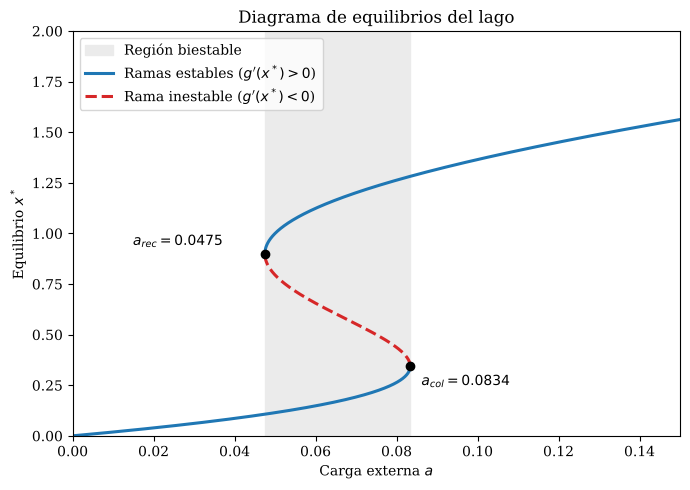

In [3]:
xs = np.linspace(0, 3, 4000)
a_eq = g(xs)
estable = dg(xs) > 0     # estable donde g'(x*) > 0

fig, ax = plt.subplots(figsize=(7, 5))
ax.axvspan(a_rec, a_col, color='0.92', label='Región biestable')
ax.plot(np.where(estable, a_eq, np.nan), xs, color='tab:blue', lw=2.2, label="Ramas estables ($g'(x^*)>0$)")
ax.plot(np.where(~estable, a_eq, np.nan), xs, color='tab:red', lw=2.2, ls='--', label="Rama inestable ($g'(x^*)<0$)")
ax.plot([a_col, a_rec], [x_col, x_rec], 'ko', ms=6, zorder=5)
ax.annotate(f"$a_{{col}}={a_col:.4f}$", (a_col, x_col), textcoords='offset points', xytext=(8, -14))
ax.annotate(f"$a_{{rec}}={a_rec:.4f}$", (a_rec, x_rec), textcoords='offset points', xytext=(-95, 6))
ax.set_xlim(0, 0.15)
ax.set_ylim(0, 2)
ax.set_xlabel('Carga externa $a$')
ax.set_ylabel('Equilibrio $x^*$')
ax.set_title('Diagrama de equilibrios del lago')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('img/task3_1c_diagrama.png', dpi=200)
plt.show()

### 3.1d – Barrido lento de la carga

Se integra con RK4 el sistema con $a(t)$ creciente y luego decreciente, a varias velocidades, y se registra el valor de $a$ donde ocurre cada salto.

a_col = 0.08339,  a_rec = 0.04749
      nu  salto sube  a - a_col  salto baja  a_rec - a
   1e-03     0.11100    0.02761     0.01810    0.02939
   3e-04     0.09657    0.01318     0.03325    0.01424
   1e-04     0.08994    0.00655     0.04025    0.00723
   3e-05     0.08637    0.00299     0.04411    0.00338
   1e-05     0.08483    0.00144     0.04582    0.00167
Exponente del retraso: sube 0.641,  baja 0.624


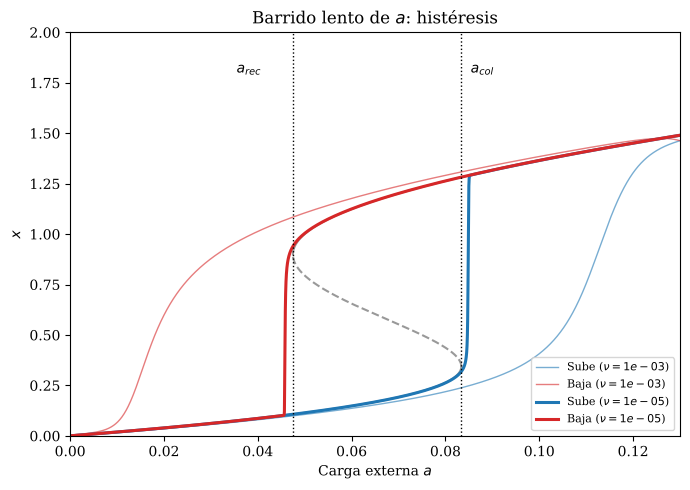

In [4]:
def rk4_rampa(x0, a_fun, T, dt):
    # RK4 para x' = f(x; a(t)) con la carga variando en el tiempo
    n = int(round(T / dt))
    x = np.empty(n + 1)
    x[0] = xi = x0
    for i in range(n):
        t = i * dt
        a_i, a_m, a_f = a_fun(t), a_fun(t + dt / 2), a_fun(t + dt)
        k1 = f(xi, a_i)
        k2 = f(xi + dt / 2 * k1, a_m)
        k3 = f(xi + dt / 2 * k2, a_m)
        k4 = f(xi + dt * k3, a_f)
        xi = xi + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        x[i + 1] = xi
    return x


# Umbrales (punto medio entre el plegamiento y la rama a la que salta) para detectar cada salto
x_alta_col = rama_alta(a_col)
x_baja_rec = rama_baja(a_rec)
umbral_sube = (x_col + x_alta_col) / 2
umbral_baja = (x_rec + x_baja_rec) / 2

dt_det = 0.05
a_min, a_max = 0.0, 0.13


def barrido(nu):
    # Sube a de a_min a a_max con velocidad nu y luego la baja de vuelta
    T = (a_max - a_min) / nu
    t = dt_det * np.arange(int(round(T / dt_det)) + 1)
    a_sube = a_min + nu * t
    x_sube = rk4_rampa(rama_baja(a_min), lambda s: a_min + nu * s, T, dt_det)
    a_baja = a_max - nu * t
    x_baja = rk4_rampa(x_sube[-1], lambda s: a_max - nu * s, T, dt_det)
    a_salto_sube = a_sube[np.argmax(x_sube > umbral_sube)]
    a_salto_baja = a_baja[np.argmax(x_baja < umbral_baja)]
    return a_sube, x_sube, a_baja, x_baja, a_salto_sube, a_salto_baja


velocidades = [1e-3, 3e-4, 1e-4, 3e-5, 1e-5]
barridos = {nu: barrido(nu) for nu in velocidades}

print(f"a_col = {a_col:.5f},  a_rec = {a_rec:.5f}")
print(f"{'nu':>8s} {'salto sube':>11s} {'a - a_col':>10s} {'salto baja':>11s} {'a_rec - a':>10s}")
for nu, r in barridos.items():
    print(f"{nu:8.0e} {r[4]:11.5f} {r[4] - a_col:10.5f} {r[5]:11.5f} {a_rec - r[5]:10.5f}")

# Exponente del retraso del salto frente a nu (ajuste log-log)
lnu = np.log([nu for nu in velocidades])
exp_sube = np.polyfit(lnu, np.log([barridos[nu][4] - a_col for nu in velocidades]), 1)[0]
exp_baja = np.polyfit(lnu, np.log([a_rec - barridos[nu][5] for nu in velocidades]), 1)[0]
print(f"Exponente del retraso: sube {exp_sube:.3f},  baja {exp_baja:.3f}")

# Figura: diagrama de equilibrios con las trayectorias de los barridos
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(np.where(estable, a_eq, np.nan), xs, color='0.6', lw=1.5)
ax.plot(np.where(~estable, a_eq, np.nan), xs, color='0.6', lw=1.5, ls='--')
for nu, lw, al in [(1e-3, 1.0, 0.6), (1e-5, 2.2, 1.0)]:
    r = barridos[nu]
    ax.plot(r[0], r[1], color='tab:blue', lw=lw, alpha=al, label=f'Sube ($\\nu={nu:.0e}$)')
    ax.plot(r[2], r[3], color='tab:red', lw=lw, alpha=al, label=f'Baja ($\\nu={nu:.0e}$)')
ax.axvline(a_col, color='k', ls=':', lw=1)
ax.axvline(a_rec, color='k', ls=':', lw=1)
ax.text(a_col + 0.002, 1.8, '$a_{col}$')
ax.text(a_rec - 0.012, 1.8, '$a_{rec}$')
ax.set_xlim(0, 0.13)
ax.set_ylim(0, 2)
ax.set_xlabel('Carga externa $a$')
ax.set_ylabel('$x$')
ax.set_title('Barrido lento de $a$: histéresis')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig('img/task3_1d_histeresis.png', dpi=200)
plt.show()

## Task 3.2 – Señales de alerta temprana

### 3.2b – Euler-Maruyama con carga creciente

Se simula $dx = f(x;a(t))\,dt + \sigma\,dW$ con $a(t)=a_0+\nu t$ hasta que el sistema salta a la rama de alta concentración.

nu = 2.085e-05,  x(0) = 0.0906
Salto (x > 0.813) en t = 2103.2, con a = 0.08554  (a_col = 0.08339)
Serie previa al salto: 40791 puntos, t_final = 2039.5


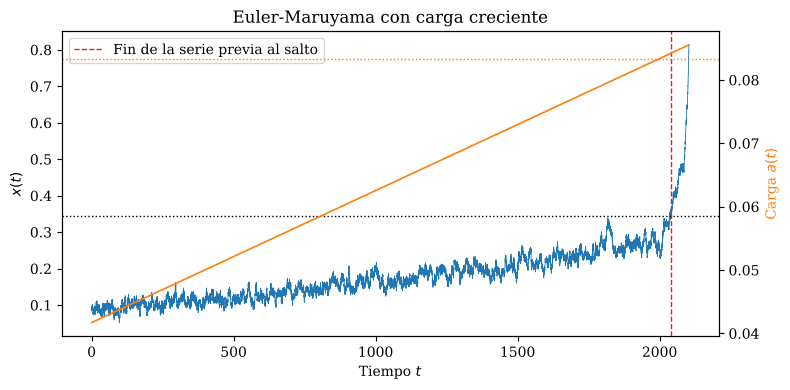

In [5]:
sigma, dt = 0.01, 0.05
T_sub = 2000.0                  # tiempo en que a llega a a_col
a0 = 0.5 * a_col                # carga inicial
nu = (a_col - a0) / T_sub       # velocidad de subida: a(t) = a0 + nu t


def euler_maruyama(rng, x0, a_fun, T, sigma, x_stop=None):
    # Euler-Maruyama: x_{n+1} = x_n + f(x_n; a_n) dt + sigma sqrt(dt) xi_n,  xi_n ~ N(0,1)
    n = int(round(T / dt))
    ruido = sigma * np.sqrt(dt) * rng.standard_normal(n)
    x = np.empty(n + 1)
    x[0] = xi = x0
    for i in range(n):
        xi = xi + f(xi, a_fun(i * dt)) * dt + ruido[i]
        x[i + 1] = xi
        if x_stop is not None and xi > x_stop:   # se detiene al saltar a la rama alta
            return x[:i + 2]
    return x


def hasta_salto(x):
    # La serie previa al salto termina en el último instante con x <= x_col (antes de abandonar la rama baja)
    i_fin = np.where(x <= x_col)[0].max()
    return x[:i_fin + 1]


rng = np.random.default_rng(42)
x_tot = euler_maruyama(rng, rama_baja(a0), lambda s: a0 + nu * s, 5 * T_sub, sigma, x_stop=umbral_sube)
x_pre = hasta_salto(x_tot)

t_tot = dt * np.arange(len(x_tot))
t_salto = t_tot[-1]
print(f"nu = {nu:.3e},  x(0) = {x_tot[0]:.4f}")
print(f"Salto (x > {umbral_sube:.3f}) en t = {t_salto:.1f}, con a = {a0 + nu * t_salto:.5f}  (a_col = {a_col:.5f})")
print(f"Serie previa al salto: {len(x_pre)} puntos, t_final = {dt * (len(x_pre) - 1):.1f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t_tot, x_tot, color='tab:blue', lw=0.6)
ax.axhline(x_col, color='k', ls=':', lw=1)
ax.axvline(dt * (len(x_pre) - 1), color='tab:red', ls='--', lw=1, label='Fin de la serie previa al salto')
ax.set_xlabel('Tiempo $t$')
ax.set_ylabel('$x(t)$')
ax2 = ax.twinx()
ax2.plot(t_tot, a0 + nu * t_tot, color='tab:orange', lw=1.2, label='$a(t)$')
ax2.axhline(a_col, color='tab:orange', ls=':', lw=1)
ax2.set_ylabel('Carga $a(t)$', color='tab:orange')
ax.set_title('Euler-Maruyama con carga creciente')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('img/task3_2b_serie.png', dpi=200)
plt.show()

### 3.2c – Detrending, varianza y autocorrelación móviles

Se elimina la tendencia con un núcleo gaussiano y se calculan la varianza y la autocorrelación de retardo uno en ventanas móviles, con sus valores teóricos superpuestos.

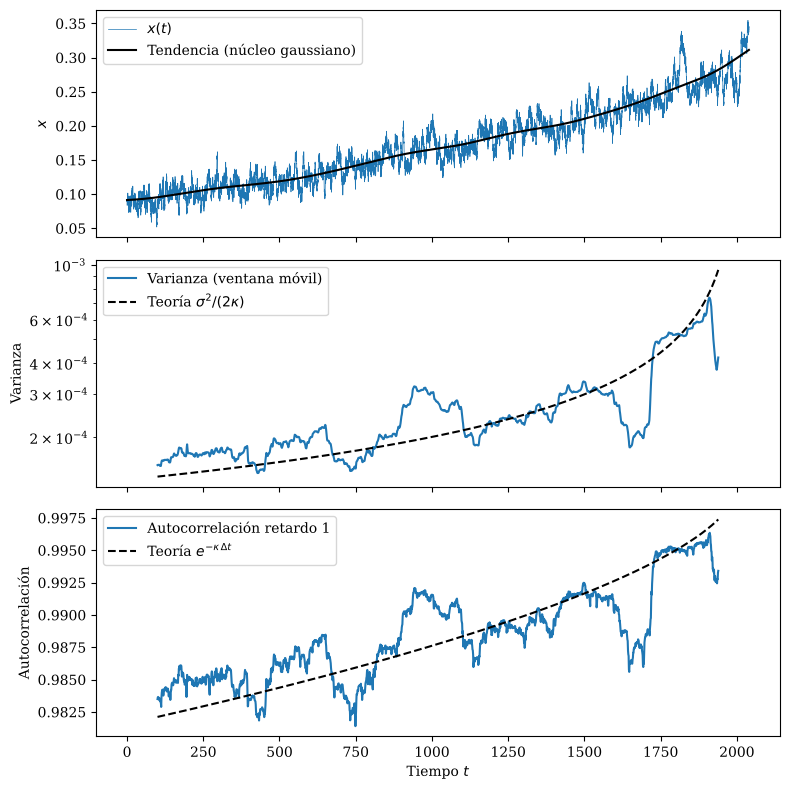

Ventana: 200 unidades de tiempo (4000 puntos); núcleo gaussiano: 100
kappa teórico: inicio 0.3609, fin 0.0524
Varianza  medida / teoría: inicio 1.11,  fin 0.44
Autocorr. medida / teoría: inicio 0.9835 / 0.9821,  fin 0.9934 / 0.9974
Error relativo esperado de la varianza por ventana: inicio 0.17, fin 0.44


In [6]:
B_det = 100.0     # ancho (desv. estándar) del núcleo gaussiano, en unidades de tiempo
W_vent = 200.0    # tamaño de la ventana móvil, en unidades de tiempo
paso_vent = 20    # desplazamiento de la ventana, en pasos de dt


def residuo(x):
    # Detrending: se resta la tendencia suavizada con un núcleo gaussiano
    return x - gaussian_filter1d(x, B_det / dt, mode='nearest')


def indicadores_moviles(r):
    # Varianza y autocorrelación de retardo uno en ventanas móviles de W puntos (sumas acumuladas)
    W = int(round(W_vent / dt))
    c1 = np.concatenate([[0.0], np.cumsum(r)])
    c2 = np.concatenate([[0.0], np.cumsum(r * r)])
    cp = np.concatenate([[0.0], np.cumsum(r[:-1] * r[1:])])
    i = np.arange(0, len(r) - W + 1, paso_vent)
    S1 = c1[i + W] - c1[i]
    m = S1 / W
    var = (c2[i + W] - c2[i] - W * m**2) / (W - 1)
    P = cp[i + W - 1] - cp[i]
    cov = (P - m * (S1 - r[i + W - 1]) - m * (S1 - r[i]) + (W - 1) * m**2) / (W - 1)
    return (i + W / 2) * dt, var, cov / var


def kappa_teo(a):
    # kappa = g'(x*) sobre la rama baja (no existe para a >= a_col)
    a = np.asarray(a, dtype=float)
    k = np.full(a.shape, np.nan)
    ok = a < a_col
    k[ok] = [dg(rama_baja(ai)) for ai in a[ok]]
    return k


tendencia = gaussian_filter1d(x_pre, B_det / dt, mode='nearest')
t_c, var_m, ac_m = indicadores_moviles(x_pre - tendencia)

kap = kappa_teo(a0 + nu * t_c)
var_t = sigma**2 / (2 * kap)       # varianza estacionaria sigma^2/(2 kappa)
ac_t = np.exp(-kap * dt)           # autocorrelación a un retardo dt: exp(-kappa dt)

t_pre = dt * np.arange(len(x_pre))
fig, axs = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
axs[0].plot(t_pre, x_pre, color='tab:blue', lw=0.5, label='$x(t)$')
axs[0].plot(t_pre, tendencia, color='k', lw=1.5, label='Tendencia (núcleo gaussiano)')
axs[0].set_ylabel('$x$')
axs[0].legend(loc='upper left')
axs[1].plot(t_c, var_m, color='tab:blue', label='Varianza (ventana móvil)')
axs[1].plot(t_c, var_t, color='k', ls='--', label='Teoría $\\sigma^2/(2\\kappa)$')
axs[1].set_yscale('log')
axs[1].set_ylabel('Varianza')
axs[1].legend(loc='upper left')
axs[2].plot(t_c, ac_m, color='tab:blue', label='Autocorrelación retardo 1')
axs[2].plot(t_c, ac_t, color='k', ls='--', label='Teoría $e^{-\\kappa\\,\\Delta t}$')
axs[2].set_ylabel('Autocorrelación')
axs[2].set_xlabel('Tiempo $t$')
axs[2].legend(loc='upper left')
plt.tight_layout()
plt.savefig('img/task3_2c_indicadores.png', dpi=200)
plt.show()

print(f"Ventana: {W_vent:.0f} unidades de tiempo ({int(W_vent / dt)} puntos); núcleo gaussiano: {B_det:.0f}")
print(f"kappa teórico: inicio {kap[0]:.4f}, fin {kap[~np.isnan(kap)][-1]:.4f}")
print(f"Varianza  medida / teoría: inicio {var_m[0] / var_t[0]:.2f},  fin {var_m[~np.isnan(var_t)][-1] / var_t[~np.isnan(var_t)][-1]:.2f}")
print(f"Autocorr. medida / teoría: inicio {ac_m[0]:.4f} / {ac_t[0]:.4f},  fin {ac_m[~np.isnan(ac_t)][-1]:.4f} / {ac_t[~np.isnan(ac_t)][-1]:.4f}")
# Error relativo del estimador de varianza en una ventana de un proceso OU: sqrt(2 / (kappa W))
print(f"Error relativo esperado de la varianza por ventana: inicio {np.sqrt(2 / (kap[0] * W_vent)):.2f}, fin {np.sqrt(2 / (kap[~np.isnan(kap)][-1] * W_vent)):.2f}")

### 3.2d – 100 realizaciones y tau de Kendall

Se repite la simulación 100 veces con semillas distintas y se calcula el tau de Kendall de cada indicador contra el tiempo.

In [7]:
def tau_indicadores(x):
    # tau de Kendall (y valor p) de la varianza y de la autocorrelación contra el tiempo
    t, v, ac = indicadores_moviles(residuo(x))
    tv, pv = kendalltau(t, v)
    ta, pa = kendalltau(t, ac)
    return tv, pv, ta, pa, v[0], ac[0], v[-1], ac[-1]   # además, niveles de la primera y la última ventana


def conjunto_rampa(sigma, T_sub, n=100, semilla=42):
    # n realizaciones independientes con a(t) = a0 + nu t, hasta el salto
    nu = (a_col - a0) / T_sub
    res, largos, a_salto = [], [], []
    for k in range(n):
        rng = np.random.default_rng([semilla, 0, k])
        x = euler_maruyama(rng, rama_baja(a0), lambda s: a0 + nu * s, 5 * T_sub, sigma, x_stop=umbral_sube)
        a_salto.append(a0 + nu * dt * (len(x) - 1))
        x_pre = hasta_salto(x)
        largos.append(len(x_pre))
        res.append(tau_indicadores(x_pre))
    return {'res': np.array(res), 'largos': np.array(largos), 'a_salto': np.array(a_salto)}


def fracciones(res):
    # Fracción con tau > 0 y p < 0.05: (varianza, autocorrelación)
    return ((res[:, 0] > 0) & (res[:, 1] < 0.05)).mean(), ((res[:, 2] > 0) & (res[:, 3] < 0.05)).mean()


base = conjunto_rampa(0.01, 2000.0)
fv, fa = fracciones(base['res'])
print(f"Realizaciones: {len(base['res'])}")
print(f"Fracción con tendencia positiva y significativa (5 %): varianza = {fv:.2f},  autocorrelación = {fa:.2f}")
print(f"tau medio: varianza = {base['res'][:, 0].mean():.3f},  autocorrelación = {base['res'][:, 2].mean():.3f}")
print(f"Largo medio de la serie previa al salto: {dt * base['largos'].mean():.0f};  a medio en el salto: {base['a_salto'].mean():.5f}")

Realizaciones: 100
Fracción con tendencia positiva y significativa (5 %): varianza = 1.00,  autocorrelación = 1.00
tau medio: varianza = 0.664,  autocorrelación = 0.659
Largo medio de la serie previa al salto: 2039;  a medio en el salto: 0.08516


### 3.2e – Control con carga constante

Se repite el experimento con $a=0.5\,a_{col}$ constante y la misma duración, para estimar la tasa de falsas alarmas.

Falsas alarmas (carga constante): varianza = 0.45,  autocorrelación = 0.44
tau medio en el control: varianza = 0.009,  autocorrelación = 0.005
tau mínimo con carga creciente: varianza = 0.42,  autocorrelación = 0.41
tau máximo con carga constante:  varianza = 0.43,  autocorrelación = 0.39


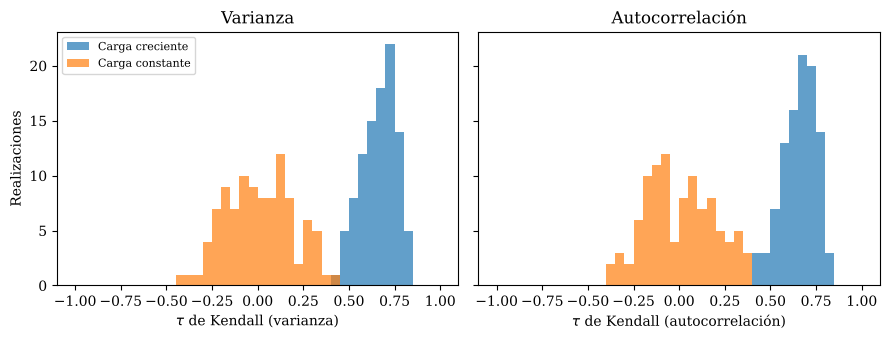

In [8]:
def conjunto_control(sigma, largos, semilla=42):
    # Carga constante a = 0.5 a_col con la misma duración que cada realización de la rampa
    res = []
    for k, L in enumerate(largos):
        rng = np.random.default_rng([semilla, 1, k])
        x = euler_maruyama(rng, rama_baja(a0), lambda s: a0, (L - 1) * dt, sigma)
        res.append(tau_indicadores(x))
    return np.array(res)


ctrl = conjunto_control(0.01, base['largos'])
cv, ca = fracciones(ctrl)
print(f"Falsas alarmas (carga constante): varianza = {cv:.2f},  autocorrelación = {ca:.2f}")
print(f"tau medio en el control: varianza = {ctrl[:, 0].mean():.3f},  autocorrelación = {ctrl[:, 2].mean():.3f}")
print(f"tau mínimo con carga creciente: varianza = {base['res'][:, 0].min():.2f},  autocorrelación = {base['res'][:, 2].min():.2f}")
print(f"tau máximo con carga constante:  varianza = {ctrl[:, 0].max():.2f},  autocorrelación = {ctrl[:, 2].max():.2f}")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for ax, j, nombre in [(axs[0], 0, 'Varianza'), (axs[1], 2, 'Autocorrelación')]:
    ax.hist(base['res'][:, j], bins=np.linspace(-1, 1, 41), alpha=0.7, color='tab:blue', label='Carga creciente')
    ax.hist(ctrl[:, j], bins=np.linspace(-1, 1, 41), alpha=0.7, color='tab:orange', label='Carga constante')
    ax.set_xlabel(f'$\\tau$ de Kendall ({nombre.lower()})')
    ax.set_title(nombre)
axs[0].set_ylabel('Realizaciones')
axs[0].legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig('img/task3_2e_tau.png', dpi=200)
plt.show()

### 3.2f – Efecto de duplicar $\sigma$ y de subir $a$ al doble de velocidad

Se repiten los experimentos con $\sigma=0.02$ y con el tiempo de subida reducido a 1000.

In [9]:
escenarios = {
    'Base (sigma=0.01, subida 2000)': (0.01, 2000.0),
    'sigma doble (0.02)': (0.02, 2000.0),
    'Subida en 1000': (0.01, 1000.0),
}
resumen, nivel = {}, {}
for nombre, (s, Ts) in escenarios.items():
    if Ts == 2000.0 and s == 0.01:
        rampa, control = base, ctrl
    else:
        rampa = conjunto_rampa(s, Ts)
        control = conjunto_control(s, rampa['largos'])
    resumen[nombre] = (fracciones(rampa['res']), fracciones(control),
                       rampa['res'][:, [0, 2]].mean(axis=0), control[:, [0, 2]].mean(axis=0),
                       dt * rampa['largos'].mean(), rampa['a_salto'].mean())
    r = rampa['res']
    nivel[nombre] = (r[:, 4].mean(), np.median(r[:, 6] / r[:, 4]), r[:, 5].mean(), r[:, 7].mean())

print(f"{'Escenario':32s} {'det.var':>8s} {'det.ac':>7s} {'FA var':>7s} {'FA ac':>6s} {'tau var':>8s} {'tau ac':>7s}")
for nombre, (dr, fa_, tr, tc_, L, aj) in resumen.items():
    print(f"{nombre:32s} {dr[0]:8.2f} {dr[1]:7.2f} {fa_[0]:7.2f} {fa_[1]:6.2f} {tr[0]:8.3f} {tr[1]:7.3f}")

print(f"\n{'Escenario':32s} {'var ini':>9s} {'var fin/ini':>12s} {'ac ini':>8s} {'ac fin':>8s} {'largo':>7s} {'a salto':>8s} {'a salto - a_col':>16s}")
for nombre, (dr, fa_, tr, tc_, L, aj) in resumen.items():
    print(f"{nombre:32s} {nivel[nombre][0]:9.2e} {nivel[nombre][1]:12.2f} {nivel[nombre][2]:8.4f} {nivel[nombre][3]:8.4f} {L:7.0f} {aj:8.5f} {aj - a_col:16.5f}")

Escenario                         det.var  det.ac  FA var  FA ac  tau var  tau ac
Base (sigma=0.01, subida 2000)       1.00    1.00    0.45   0.44    0.664   0.659
sigma doble (0.02)                   1.00    1.00    0.43   0.43    0.637   0.632
Subida en 1000                       1.00    1.00    0.38   0.38    0.678   0.666

Escenario                          var ini  var fin/ini   ac ini   ac fin   largo  a salto  a salto - a_col
Base (sigma=0.01, subida 2000)    1.30e-04         4.85   0.9800   0.9953    2039  0.08516          0.00177
sigma doble (0.02)                5.24e-04         3.83   0.9802   0.9942    1961  0.08335         -0.00003
Subida en 1000                    1.34e-04         3.94   0.9806   0.9945    1035  0.08663          0.00324
